# Task 1 – Retail Performance Analytics

## 1. Data Preparation and Quality Assessment

This section loads the retail dataset and examines its structure, data types and overall quality before carrying out further analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the retail dataset
df = pd.read_csv("../data/Retail_regions.csv")

# Display the first five rows
display(df.head())

,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1030,South,Retail Park,5216.025748,1360.669726,15143.645217,274.440248,24.246254,84.013149,83.191515,19.065964,46154.901846,Summer,148983.86
1,1013,North,Town,2589.258613,1759.537410,9575.301668,354.439564,33.884441,76.316110,86.923332,15.905459,44674.788107,Autumn,164838.92
2,1022,North,Retail Park,5236.467946,1444.458541,NaN,343.287855,37.862522,79.487759,90.428512,9.477576,48924.722661,Summer,152132.29
3,1094,North,Mall,5848.627748,1369.644357,6489.545492,408.194166,23.574998,63.922735,80.859629,11.220010,52203.354247,Autumn,165743.22
4,1037,North,Retail Park,6647.672155,1073.218324,13003.156557,390.722992,4.795855,58.007873,94.395740,14.487711,33369.483674,Winter,160706.11


In [2]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Generate summary statistics
display(df.describe())

Dataset shape: (5100, 14)
<class 'pandas.DataFrame'>
RangeIndex: 5100 entries, 0 to 5099
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   StoreID                5100 non-null   int64  
 1   Region                 5100 non-null   str    
 2   StoreType              5100 non-null   str    
 3   MarketingSpend         4743 non-null   float64
 4   Footfall               5100 non-null   float64
 5   OnlineTraffic          4744 non-null   float64
 6   StaffHours             5100 non-null   float64
 7   DiscountRate           5100 non-null   float64
 8   CustomerSatisfaction   4744 non-null   float64
 9   InventoryAvailability  4741 non-null   float64
 10  CompetitorDistance     5100 non-null   float64
 11  PreviousMonthSales     5100 non-null   float64
 12  Season                 5100 non-null   str    
 13  SalesRevenue           5100 non-null   float64
dtypes: float64(10), int64(1), str(3)
memory u

,StoreID,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,SalesRevenue
count,5100.000000,4743.000000,5100.000000,4744.000000,5100.000000,5100.000000,4744.000000,4741.000000,5100.000000,5100.000000,5100.000000
mean,1049.660588,5390.110020,1203.562926,8516.080623,348.755755,19.988718,75.140666,85.018529,10.422443,44917.977123,151847.897763
std,28.874010,4155.709377,350.261857,2491.154051,79.969887,11.529909,9.909915,7.778717,5.685814,9123.567050,19674.928009
min,1000.000000,250.000000,100.000000,500.000000,53.587999,0.003150,41.787013,54.739076,0.500308,11690.052009,74891.800000
25%,1024.000000,4032.469498,973.247323,6826.193915,294.625585,10.240444,68.473753,79.650081,5.457909,38774.357137,138245.825000
50%,1050.000000,5027.134224,1202.963709,8503.116153,348.409324,19.835683,75.238566,85.111935,10.463094,44975.798836,151883.290000
75%,1075.000000,6034.078029,1436.574918,10152.623985,403.279337,30.002817,82.054071,90.541148,15.403430,50821.407852,165237.182500
max,1099.000000,65814.623356,2540.423760,17781.988363,651.294406,39.990952,100.000000,100.000000,19.996876,75993.624564,232503.990000


### 1.1 Missing Value Analysis

This section identifies missing values within the retail dataset and calculates the percentage of missing data for each affected column.

In [3]:
# Calculate missing values
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage Missing": (df.isnull().sum() / len(df)) * 100
})

# Display columns containing missing values
missing_values = missing_values[missing_values["Missing Values"] > 0]

display(missing_values.round(2))

,Missing Values,Percentage Missing
MarketingSpend,357,7.00
OnlineTraffic,356,6.98
CustomerSatisfaction,356,6.98
InventoryAvailability,359,7.04


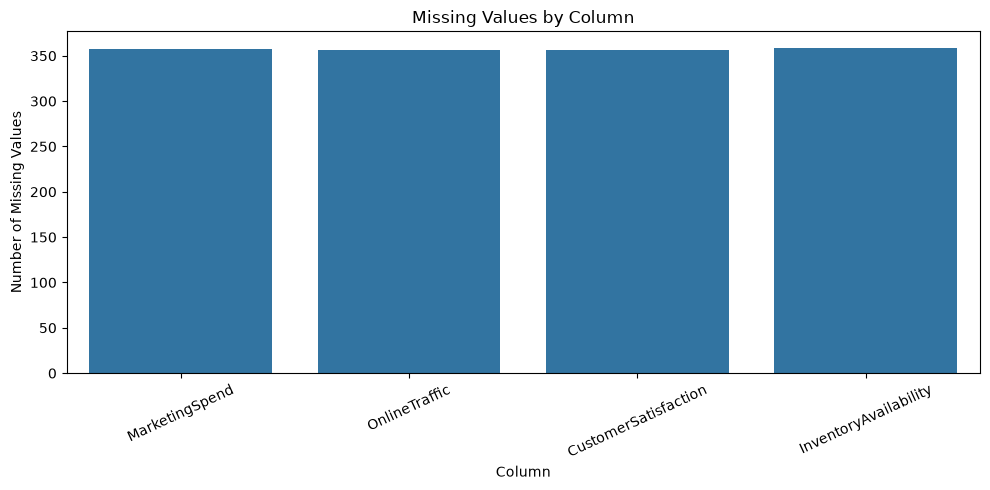

In [4]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_values.index,
    y=missing_values["Missing Values"]
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### 1.2 Duplicate Analysis

This section identifies exact duplicate records within the dataset to assess data quality and avoid counting identical records more than once.

In [5]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Display duplicate records
display(df[df.duplicated(keep=False)].head(10))

Number of duplicate rows: 100


,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
23,1018,North,Retail Park,4742.653237,1091.791358,11894.791304,394.001867,15.913648,68.178716,91.815822,7.614217,56860.259014,Summer,146273.44
29,1019,West,Retail Park,6384.241384,1313.924255,13093.428633,258.202657,14.184262,79.449115,97.402876,17.312193,40990.461294,Autumn,149898.45
65,1070,West,Retail Park,5792.747213,1258.986544,NaN,351.708998,22.607532,78.973921,99.684177,11.775668,42023.362783,Autumn,173008.39
79,1071,North,Mall,NaN,1618.548420,7577.383648,283.009449,25.634623,94.828299,89.898813,2.930329,53221.841299,Winter,157007.89
84,1028,East,Town,4166.756754,1122.307610,8244.283411,238.207515,31.811704,77.877646,85.303761,19.183453,38683.945167,Winter,133972.23
106,1046,East,Retail Park,3050.097819,1185.783727,9199.608015,343.558241,2.481111,82.479397,71.505129,14.698768,43475.486668,Spring,137730.76
157,1002,East,Retail Park,4425.731227,973.234337,8401.997072,390.255118,13.330226,61.001539,67.702158,15.653640,34108.731633,Autumn,133226.13
168,1093,South,Town,NaN,903.224364,8105.579694,362.215229,16.508392,92.275368,95.340513,19.164297,48167.467636,Winter,174360.97
227,1093,East,Mall,5101.740810,1443.253738,12661.950674,417.012150,4.577638,48.638198,77.380073,6.250909,49055.540609,Summer,162334.96
228,1046,East,Retail Park,5452.216484,1990.829807,7737.053143,373.374722,24.626586,94.352622,97.081711,4.201391,42488.743968,Winter,194861.25


### 1.3 Data Cleaning

Exact duplicate records are removed to prevent identical rows from being counted multiple times. Missing numerical values are replaced using the median of their respective columns. The median is used because it is less affected by extreme values than the mean.

In [6]:
# Create a cleaned copy of the original dataset
df_clean = df.drop_duplicates().copy()

# Identify numerical columns with missing values
columns_to_impute = [
    "MarketingSpend",
    "OnlineTraffic",
    "CustomerSatisfaction",
    "InventoryAvailability"
]

# Replace missing values using each column's median
for column in columns_to_impute:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

# Check the cleaned dataset
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nRemaining duplicate rows:", df_clean.duplicated().sum())

Original dataset shape: (5100, 14)
Cleaned dataset shape: (5000, 14)

Remaining missing values:
StoreID                  0
Region                   0
StoreType                0
MarketingSpend           0
Footfall                 0
OnlineTraffic            0
StaffHours               0
DiscountRate             0
CustomerSatisfaction     0
InventoryAvailability    0
CompetitorDistance       0
PreviousMonthSales       0
Season                   0
SalesRevenue             0
dtype: int64

Remaining duplicate rows: 0


### 1.4 Outlier Investigation

The Interquartile Range (IQR) method is used to identify potential outliers in numerical variables. These observations are investigated rather than automatically removed, as unusually high or low values may represent genuine retail business activity.

In [7]:
# Select numerical columns, excluding StoreID
numeric_columns = df_clean.select_dtypes(include=np.number).columns.drop("StoreID")

# Calculate potential outliers using the IQR method
outlier_results = []

for column in numeric_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_results.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Column,Lower Bound,Upper Bound,Outlier Count
0,MarketingSpend,1394.13,8656.68,123
1,Footfall,279.32,2129.11,43
2,OnlineTraffic,2421.61,14533.20,69
3,StaffHours,131.01,566.72,33
4,DiscountRate,-19.75,59.93,0
5,CustomerSatisfaction,50.62,99.96,61
6,InventoryAvailability,64.95,105.03,29
7,CompetitorDistance,-9.38,30.27,0
8,PreviousMonthSales,20646.77,68981.28,47
9,SalesRevenue,97637.44,205657.18,30


### Outlier Analysis Interpretation

The IQR analysis identified potential outliers across several numerical variables. MarketingSpend contained the highest number of potential outliers (123), followed by OnlineTraffic (69) and CustomerSatisfaction (61). DiscountRate and CompetitorDistance contained no potential outliers.

The identified outliers were retained because unusually high or low values may represent genuine retail business activity rather than incorrect data. Removing these observations could result in losing useful information about store performance.

### 1.5 Feature Engineering

Feature engineering involves creating additional variables from existing dataset columns. These features provide further information about retail performance, sales growth, marketing efficiency and operational performance.

In [8]:
# Sales growth
df_clean["SalesGrowth"] = (
    df_clean["SalesRevenue"] - df_clean["PreviousMonthSales"]
)

# Sales growth percentage
df_clean["SalesGrowthPercentage"] = (
    df_clean["SalesGrowth"] / df_clean["PreviousMonthSales"]
) * 100

# Marketing spend per visitor
df_clean["MarketingSpendPerVisitor"] = (
    df_clean["MarketingSpend"] / df_clean["Footfall"]
)

# Footfall per staff hour
df_clean["FootfallPerStaffHour"] = (
    df_clean["Footfall"] / df_clean["StaffHours"]
)

# Marketing spend per staff hour
df_clean["MarketingSpendPerStaffHour"] = (
    df_clean["MarketingSpend"] / df_clean["StaffHours"]
)

# Inventory shortfall
df_clean["InventoryShortfall"] = (
    100 - df_clean["InventoryAvailability"]
)

# Display the new features
display(df_clean.head())

print("Updated dataset shape:", df_clean.shape)

,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue,SalesGrowth,SalesGrowthPercentage,MarketingSpendPerVisitor,FootfallPerStaffHour,MarketingSpendPerStaffHour,InventoryShortfall
0,1030,South,Retail Park,5216.025748,1360.669726,15143.645217,274.440248,24.246254,84.013149,83.191515,19.065964,46154.901846,Summer,148983.86,102828.958154,222.790980,3.833425,4.957982,19.006052,16.808485
1,1013,North,Town,2589.258613,1759.537410,9575.301668,354.439564,33.884441,76.316110,86.923332,15.905459,44674.788107,Autumn,164838.92,120164.131893,268.975270,1.471556,4.964280,7.305219,13.076668
2,1022,North,Retail Park,5236.467946,1444.458541,8518.683811,343.287855,37.862522,79.487759,90.428512,9.477576,48924.722661,Summer,152132.29,103207.567339,210.951768,3.625212,4.207718,15.253869,9.571488
3,1094,North,Mall,5848.627748,1369.644357,6489.545492,408.194166,23.574998,63.922735,80.859629,11.220010,52203.354247,Autumn,165743.22,113539.865753,217.495346,4.270180,3.355375,14.328053,19.140371
4,1037,North,Retail Park,6647.672155,1073.218324,13003.156557,390.722992,4.795855,58.007873,94.395740,14.487711,33369.483674,Winter,160706.11,127336.626326,381.596034,6.194147,2.746750,17.013773,5.604260


Updated dataset shape: (5000, 20)


### 1.6 Data Quality Summary

The original retail dataset contained 5,100 records and 14 columns. During data preparation, 100 exact duplicate records were identified and removed. Missing values were found in four numerical columns and replaced using median imputation.

The IQR method was used to investigate potential outliers. These observations were retained because they may represent genuine retail activity. Six additional features were engineered to provide further information about sales growth, marketing efficiency, staff productivity and inventory availability.

Following data preparation, the cleaned dataset contained 5,000 records and 20 columns, with no remaining missing values or duplicate rows.

## 2. Exploratory Data Analysis

### 2.1 Sales Performance by Region

This analysis compares retail sales performance across the four regions. Total revenue, average revenue and average footfall are examined to identify differences in regional performance.

In [9]:
# Group sales data by region
region_analysis = df_clean.groupby("Region").agg(
    TotalRevenue=("SalesRevenue", "sum"),
    AverageRevenue=("SalesRevenue", "mean"),
    AverageFootfall=("Footfall", "mean"),
    AverageMarketingSpend=("MarketingSpend", "mean"),
    StoreRecords=("StoreID", "count")
).sort_values(by="TotalRevenue", ascending=False)

display(region_analysis.round(2))

,TotalRevenue,AverageRevenue,AverageFootfall,AverageMarketingSpend,StoreRecords
Region,,,,,
North,1.918892e+08,149098.07,1204.37,5545.09,1287
East,1.917392e+08,149796.29,1203.79,5289.15,1280
West,1.889283e+08,153226.54,1208.56,5223.73,1233
South,1.862428e+08,155202.32,1196.00,5417.87,1200


The regional analysis shows that the North generated the highest total revenue, followed closely by the East. The South recorded the lowest total revenue but had the highest average revenue per record. This demonstrates that total revenue and average revenue can provide different perspectives on regional performance. The results also show differences in average footfall and marketing expenditure across the four regions.

### 2.2 Sales Performance by Store Type

This analysis compares revenue and operational performance across different store types to identify differences in retail performance.

In [10]:
store_type_analysis = df_clean.groupby("StoreType").agg(
    TotalRevenue=("SalesRevenue", "sum"),
    AverageRevenue=("SalesRevenue", "mean"),
    AverageFootfall=("Footfall", "mean"),
    AverageMarketingSpend=("MarketingSpend", "mean"),
    StoreRecords=("StoreID", "count")
).sort_values(by="TotalRevenue", ascending=False)

display(store_type_analysis.round(2))

,TotalRevenue,AverageRevenue,AverageFootfall,AverageMarketingSpend,StoreRecords
StoreType,,,,,
Mall,2.611461e+08,151652.77,1208.37,5395.80,1722
Town,2.502298e+08,152393.32,1199.68,5376.36,1642
Retail Park,2.474237e+08,151236.97,1201.42,5335.81,1636


The store type analysis shows that Mall stores generated the highest total revenue, followed by Town stores and Retail Park stores. Mall stores also recorded the highest average footfall. However, Town stores achieved the highest average revenue per record. These findings highlight differences in sales performance across store types.

### 2.3 Seasonal Sales Performance

This analysis examines retail revenue across different seasons to identify seasonal trends and differences in sales performance.

In [11]:
season_analysis = df_clean.groupby("Season").agg(
    TotalRevenue=("SalesRevenue", "sum"),
    AverageRevenue=("SalesRevenue", "mean"),
    AverageFootfall=("Footfall", "mean"),
    AverageMarketingSpend=("MarketingSpend", "mean"),
    StoreRecords=("StoreID", "count")
).sort_values(by="TotalRevenue", ascending=False)

display(season_analysis.round(2))

,TotalRevenue,AverageRevenue,AverageFootfall,AverageMarketingSpend,StoreRecords
Season,,,,,
Summer,1.978087e+08,152395.00,1205.82,5355.10,1298
Winter,1.890857e+08,151389.67,1211.24,5397.28,1249
Autumn,1.881390e+08,151602.76,1199.09,5544.55,1241
Spring,1.837662e+08,151622.24,1196.51,5178.24,1212


The seasonal analysis shows that Summer generated the highest total revenue, while Spring recorded the lowest. Summer also achieved the highest average revenue per record. Winter recorded the highest average footfall, suggesting that higher customer footfall does not necessarily correspond to the highest total revenue. These findings highlight differences in retail performance across the seasons.

### 2.4 Top Five StoreIDs by Revenue

This analysis identifies the five StoreIDs associated with the highest total recorded sales revenue, allowing comparisons of revenue performance across store identifiers.

In [12]:
top_5_stores = (
    df_clean.groupby("StoreID")
    .agg(
        TotalRevenue=("SalesRevenue", "sum"),
        AverageRevenue=("SalesRevenue", "mean"),
        RecordCount=("SalesRevenue", "count")
    )
    .sort_values(by="TotalRevenue", ascending=False)
    .head(5)
)

display(top_5_stores.round(2))

,TotalRevenue,AverageRevenue,RecordCount
StoreID,,,
1057,10523014.39,150328.78,70
1040,10120753.31,155703.90,65
1086,9844891.39,151459.87,65
1083,9657864.22,148582.53,65
1020,9639258.21,150613.41,64


The analysis identified StoreID 1057 as having the highest total recorded revenue, followed by StoreIDs 1040, 1086, 1083 and 1020. However, StoreID 1040 achieved the highest average revenue per record. This demonstrates that the highest total revenue does not necessarily correspond to the highest average revenue. StoreID values are repeated across regions and store types, so these results represent performance by identifier rather than confirmed individual physical stores.

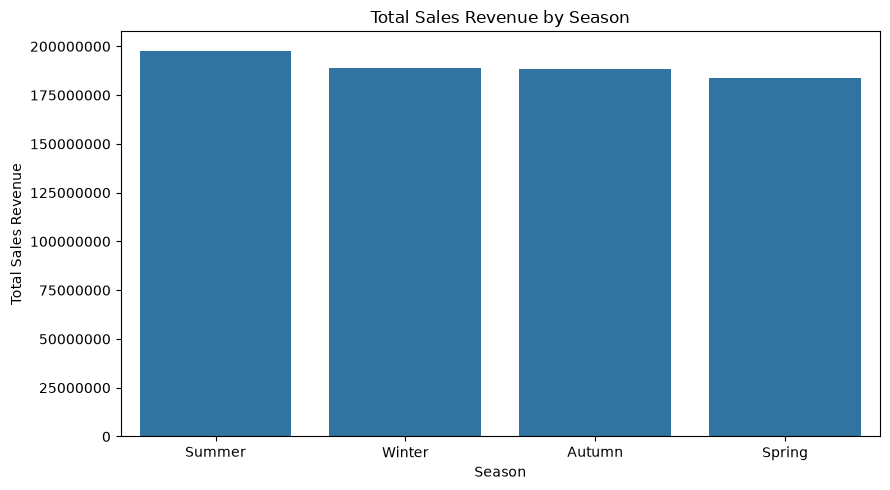

In [13]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=season_analysis.index,
    y=season_analysis["TotalRevenue"]
)

plt.title("Total Sales Revenue by Season")
plt.xlabel("Season")
plt.ylabel("Total Sales Revenue")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

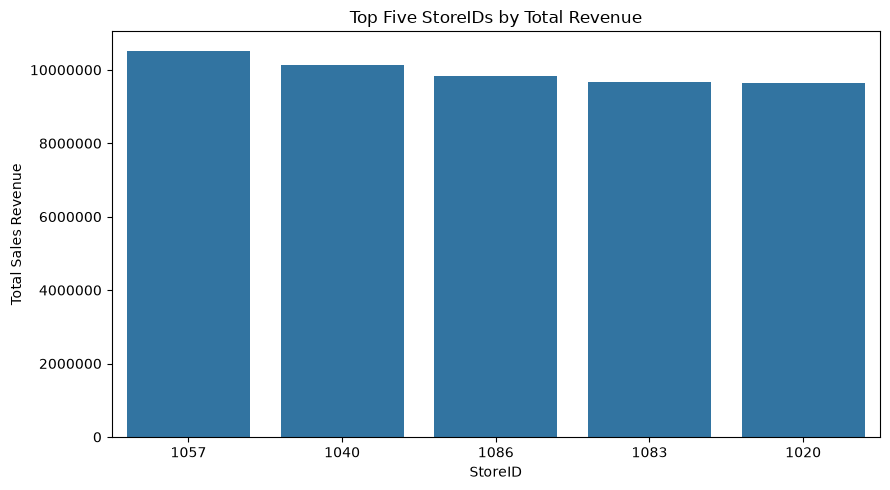

In [14]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=top_5_stores.index.astype(str),
    y=top_5_stores["TotalRevenue"]
)

plt.title("Top Five StoreIDs by Total Revenue")
plt.xlabel("StoreID")
plt.ylabel("Total Sales Revenue")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

### 2.5 Pivot Table Analysis

#### Pivot Table 1 – Average Revenue by Region and Store Type

This pivot table compares average sales revenue across regions and store types to identify differences in retail performance.

In [15]:
pivot_region_store = pd.pivot_table(
    df_clean,
    values="SalesRevenue",
    index="Region",
    columns="StoreType",
    aggfunc="mean"
)

display(pivot_region_store.round(2))

StoreType,Mall,Retail Park,Town
Region,,,
East,150080.45,148953.56,150373.47
North,148328.11,148747.46,150307.41
South,155309.01,154911.61,155370.05
West,153681.07,152611.01,153393.97


#### Pivot Table 2 – Average Revenue by Season and Store Type

This pivot table compares average sales revenue across seasons and store types to investigate seasonal differences in store performance.

In [16]:
pivot_season_store = pd.pivot_table(
    df_clean,
    values="SalesRevenue",
    index="Season",
    columns="StoreType",
    aggfunc="mean"
)

display(pivot_season_store.round(2))

StoreType,Mall,Retail Park,Town
Season,,,
Autumn,151464.24,150239.80,153085.91
Spring,151692.55,151451.92,151709.08
Summer,152447.47,151985.90,152754.18
Winter,150936.40,151225.43,152036.11


The first pivot table highlights differences in average revenue across regions and store types. The South generally records stronger average revenue, while Town stores perform particularly well across several regions.

The second pivot table shows that Summer achieves the highest average revenue across all three store types. Town stores consistently record the highest average revenue across the seasons. These results highlight the importance of considering both seasonal and store type differences when analysing retail performance.

### 2.6 Correlation Analysis

Correlation analysis is used to investigate relationships between numerical variables in the retail dataset. A correlation matrix and heatmap help identify variables that have stronger positive or negative associations with SalesRevenue.

In [17]:
# Select numerical columns, excluding StoreID
correlation_data = df_clean.select_dtypes(include=np.number).drop(
    columns=["StoreID"]
)

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Display correlations with SalesRevenue
sales_correlations = correlation_matrix["SalesRevenue"].sort_values(
    ascending=False
)

display(sales_correlations.round(3))

SalesRevenue                  1.000
SalesGrowth                   0.908
StaffHours                    0.576
SalesGrowthPercentage         0.476
Footfall                      0.412
InventoryAvailability         0.296
MarketingSpend                0.036
DiscountRate                  0.024
OnlineTraffic                 0.006
CompetitorDistance            0.002
PreviousMonthSales           -0.008
CustomerSatisfaction         -0.013
FootfallPerStaffHour         -0.075
MarketingSpendPerVisitor     -0.147
MarketingSpendPerStaffHour   -0.147
InventoryShortfall           -0.296
Name: SalesRevenue, dtype: float64

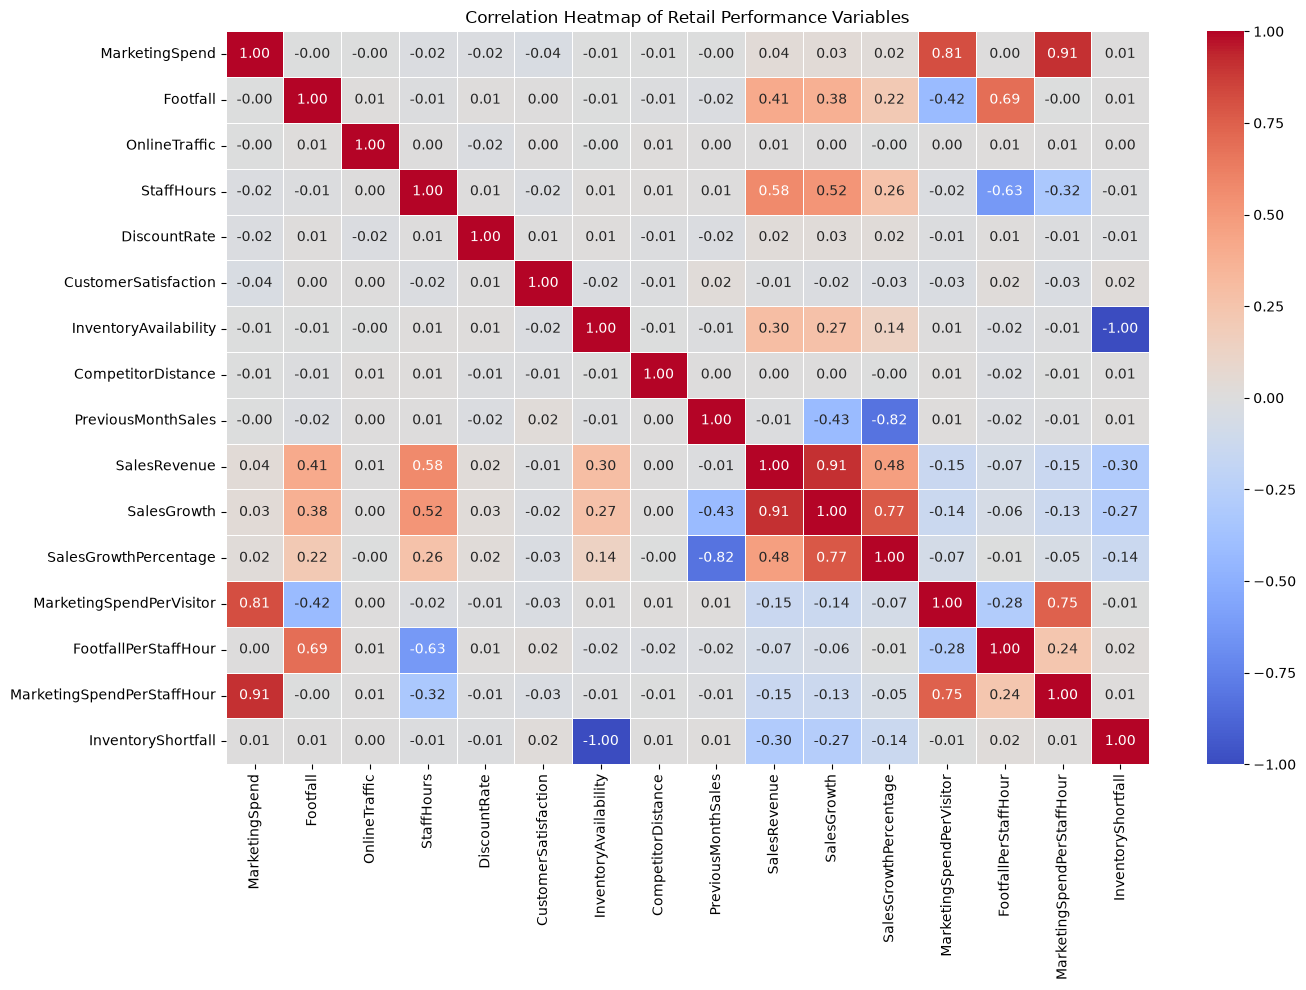

In [18]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Retail Performance Variables")
plt.tight_layout()
plt.show()

### Correlation Analysis Interpretation

The correlation analysis identified StaffHours as the strongest non-derived variable positively associated with SalesRevenue, with a correlation of 0.576. Footfall also showed a positive relationship with SalesRevenue (0.412), followed by InventoryAvailability (0.296).

MarketingSpend (0.036), OnlineTraffic (0.006) and CustomerSatisfaction (-0.013) showed very weak linear relationships with SalesRevenue in this dataset.

SalesGrowth and SalesGrowthPercentage showed stronger correlations with SalesRevenue, but these features were derived using SalesRevenue itself. Therefore, they will be excluded from predictive modelling to prevent data leakage. Correlation indicates association rather than causation.

## 3. Predictive Analytics

Two predictive models, Linear Regression and Random Forest Regression, are developed and compared to predict SalesRevenue. The dataset is divided into training and testing sets to evaluate model performance on unseen data.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select input features, excluding target and leakage columns
features = [
    "Region",
    "StoreType",
    "Season",
    "MarketingSpend",
    "Footfall",
    "OnlineTraffic",
    "StaffHours",
    "DiscountRate",
    "CustomerSatisfaction",
    "InventoryAvailability",
    "CompetitorDistance",
    "PreviousMonthSales",
    "MarketingSpendPerVisitor",
    "FootfallPerStaffHour",
    "MarketingSpendPerStaffHour",
    "InventoryShortfall"
]

# Define input variables and target
X = df_clean[features]
y = df_clean["SalesRevenue"]

# Identify numerical and categorical columns
categorical_features = ["Region", "StoreType", "Season"]

numerical_features = [
    column for column in features
    if column not in categorical_features
]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 16)
Testing data: (1000, 16)


In [20]:
# Preprocessing for numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


### 3.1 Linear Regression Model

Linear Regression is used as a baseline predictive model to estimate sales revenue based on the selected retail performance variables.

In [21]:
# Create Linear Regression pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

# Generate predictions
linear_predictions = linear_model.predict(X_test)

# Evaluate model
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")
print("--------------------------")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R²:", round(linear_r2, 4))

Linear Regression Results
--------------------------
MAE: 9721.51
RMSE: 12254.09
R²: 0.5993


### 3.2 Random Forest Regression Model

Random Forest Regression is used as a second predictive model. It combines multiple decision trees to capture potentially more complex relationships between retail performance variables and sales revenue.

In [22]:
# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Generate predictions
rf_predictions = random_forest_model.predict(X_test)

# Evaluate model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("---------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R²:", round(rf_r2, 4))

Random Forest Results
---------------------
MAE: 10100.29
RMSE: 12699.7
R²: 0.5697


In [23]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R2": [linear_r2, rf_r2]
})

display(model_comparison.round(4))

,Model,MAE,RMSE,R2
0,Linear Regression,9721.5099,12254.0920,0.5993
1,Random Forest,10100.2917,12699.6961,0.5697


### 3.3 Model Comparison and Evaluation

The Linear Regression model achieved an MAE of 9,721.51, RMSE of 12,254.09 and R² score of 0.5993. The Random Forest model achieved an MAE of 10,100.29, RMSE of 12,699.70 and R² score of 0.5697.

Linear Regression performed better across all three evaluation metrics, producing lower prediction errors and a higher R² score. This indicates that Linear Regression was the stronger predictive model for this dataset.

However, the R² score of 0.5993 indicates that approximately 59.93% of the variation in sales revenue was explained by the model. Further improvements may be needed to increase predictive accuracy.

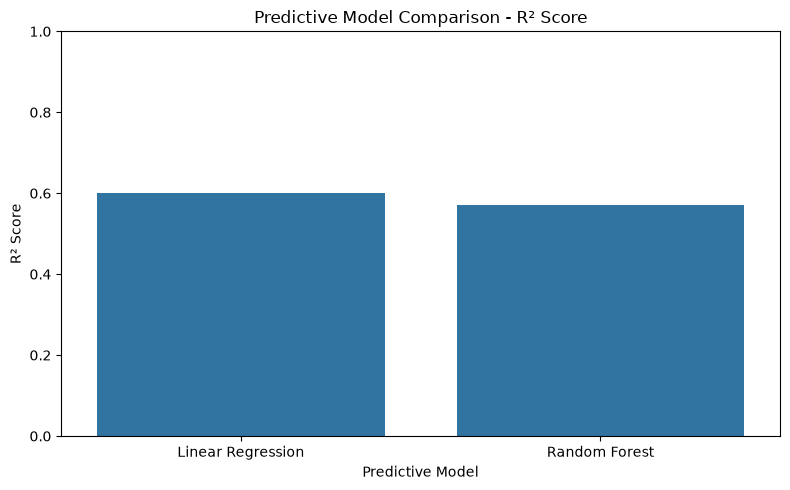

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="R2"
)

plt.title("Predictive Model Comparison - R² Score")
plt.xlabel("Predictive Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [27]:
# Extract feature importance from Random Forest
rf_estimator = random_forest_model.named_steps["model"]

# Get transformed feature names
feature_names = (
    random_forest_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_estimator.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(feature_importance.round(4))

,Feature,Importance
3,num__StaffHours,0.3779
1,num__Footfall,0.1943
12,num__InventoryShortfall,0.0658
6,num__InventoryAvailability,0.0609
2,num__OnlineTraffic,0.0339
7,num__CompetitorDistance,0.0313
8,num__PreviousMonthSales,0.0313
4,num__DiscountRate,0.0310
5,num__CustomerSatisfaction,0.0307
10,num__FootfallPerStaffHour,0.0305


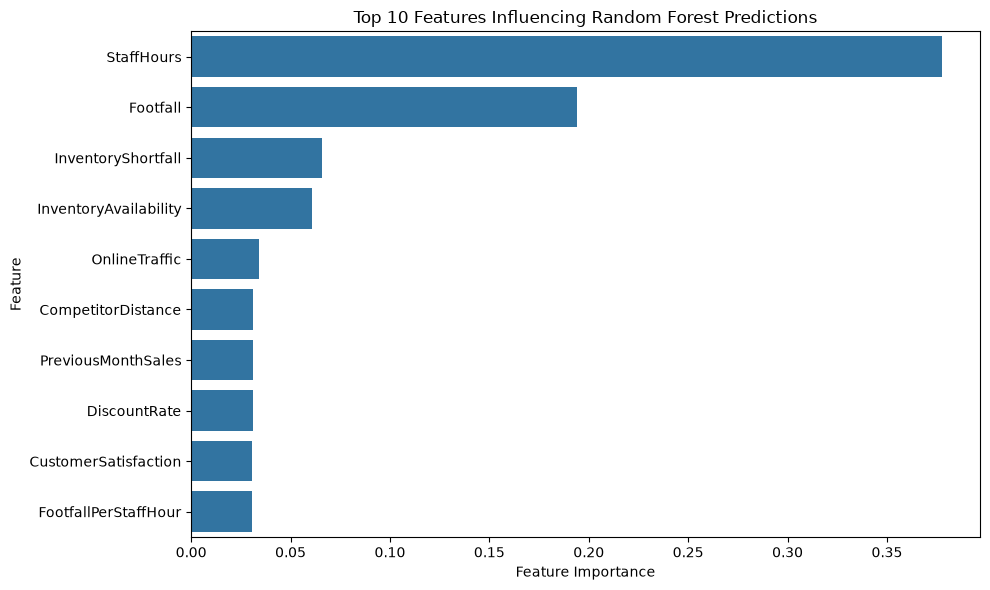

In [28]:
top_features = feature_importance.head(10).copy()

# Remove preprocessing prefixes for cleaner chart labels
top_features["Feature"] = top_features["Feature"].str.replace(
    r"^(num__|cat__)", "", regex=True
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Influencing Random Forest Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()